# Ejercicio 7 — Red Wi-Fi

Análisis de los datos originales del centro. Se eliminan duplicados exactos; no se imputan valores ausentes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargamos los datos y eliminamos duplicados exactos.
df = pd.read_csv('centro_fp_monitorizacion.csv')
print('Dimensiones originales:', df.shape)
print('Duplicados:', df.duplicated().sum())
print('Ausentes por columna:', df.isna().sum())
df = df.drop_duplicates().copy()


Dimensiones originales: (363, 12)
Duplicados: 3
Ausentes por columna: fecha                0
dia                  0
hora                 0
aula                 0
alumnos              0
temperatura_c        0
humedad_pct          0
co2_ppm              6
consumo_kwh          0
dispositivos_wifi    0
desconexiones        0
latencia_ms          0
dtype: int64


In [2]:
df['cortes'] = df['desconexiones'] >= 4
df['latencia_alta'] = df['latencia_ms'] > 100
df['incidencia'] = df['cortes'] | df['latencia_alta']
display(df.groupby('aula').agg(cortes_totales=('desconexiones','sum'), latencia_media=('latencia_ms','mean'), dispositivos_medios=('dispositivos_wifi','mean'), incidencias=('incidencia','sum')).round(2))
display(df.groupby(['hora','aula'])['incidencia'].sum().unstack())
incidencias = df[df['incidencia']]
display(incidencias)
incidencias.to_json('incidencias_wifi.json', orient='records', indent=4, force_ascii=False)
print(df[['dispositivos_wifi','desconexiones','latencia_ms']].corr())
print('Solo cortes:', (df['cortes'] & ~df['latencia_alta']).sum())
print('Solo latencia:', (~df['cortes'] & df['latencia_alta']).sum())
print('Ambas:', (df['cortes'] & df['latencia_alta']).sum())


,cortes_totales,latencia_media,dispositivos_medios,incidencias
aula,,,,
A,112,57.36,19.77,0
B,118,58.12,19.80,0
C,342,80.17,20.85,30


aula,A,B,C
hora,,,
8,0,0,0
9,0,0,0
10,0,0,0
11,0,0,0
12,0,0,0
13,0,0,0
14,0,0,10
15,0,0,10
16,0,0,10


,fecha,dia,hora,aula,alumnos,temperatura_c,humedad_pct,co2_ppm,consumo_kwh,dispositivos_wifi,desconexiones,latencia_ms,cortes,latencia_alta,incidencia
30,2026-10-01,1,14,C,17,23.6,59.7,780.0,2.86,22,7,119.8,True,True,True
31,2026-10-01,1,15,C,23,22.3,63.3,897.0,3.57,30,8,136.2,True,True,True
32,2026-10-01,1,16,C,16,21.1,51.7,661.0,2.80,20,9,130.8,True,True,True
66,2026-10-02,2,14,C,20,24.4,54.3,863.0,3.11,28,8,135.3,True,True,True
67,2026-10-02,2,15,C,28,22.4,53.4,1113.0,3.96,28,9,158.9,True,True,True
68,2026-10-02,2,16,C,14,24.0,49.4,715.0,2.41,22,7,117.0,True,True,True
102,2026-10-03,3,14,C,15,24.2,43.1,762.0,2.64,15,9,129.4,True,True,True
103,2026-10-03,3,15,C,26,23.9,52.2,1065.0,3.93,28,12,184.1,True,True,True
104,2026-10-03,3,16,C,25,23.2,59.3,914.0,3.71,26,6,119.6,True,True,True
138,2026-10-04,4,14,C,14,23.5,53.7,731.0,2.31,17,8,136.6,True,True,True


                   dispositivos_wifi  desconexiones  latencia_ms
dispositivos_wifi           1.000000       0.245223     0.579534
desconexiones               0.245223       1.000000     0.909582
latencia_ms                 0.579534       0.909582     1.000000
Solo cortes: 1
Solo latencia: 0
Ambas: 29


<Figure size 800x400 with 0 Axes>

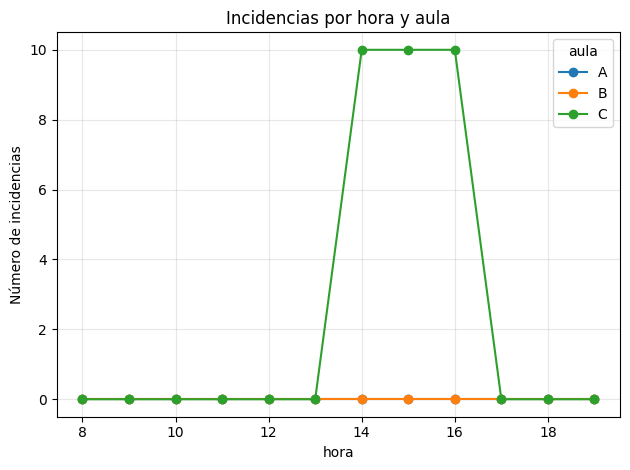

In [3]:
plt.figure(figsize=(8, 4))
df.groupby(['hora','aula'])['incidencia'].sum().unstack().plot(marker='o')
plt.title('Incidencias por hora y aula')
plt.ylabel('Número de incidencias')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('grafica_1.jpg', dpi=150)
plt.show()
plt.close()

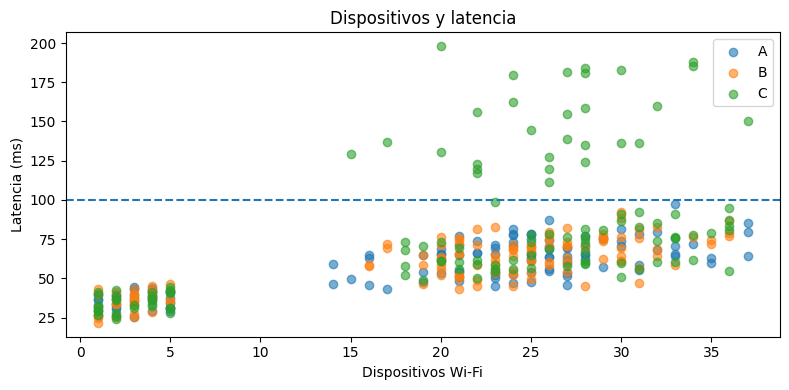

In [4]:
plt.figure(figsize=(8, 4))
for aula in df['aula'].unique():
    datos = df[df['aula']==aula]
    plt.scatter(datos['dispositivos_wifi'],datos['latencia_ms'],label=aula,alpha=0.6)
plt.axhline(100,linestyle='--')
plt.xlabel('Dispositivos Wi-Fi')
plt.ylabel('Latencia (ms)')
plt.title('Dispositivos y latencia')
plt.legend()
plt.tight_layout()
plt.savefig('grafica_2.jpg', dpi=150)
plt.show()
plt.close()

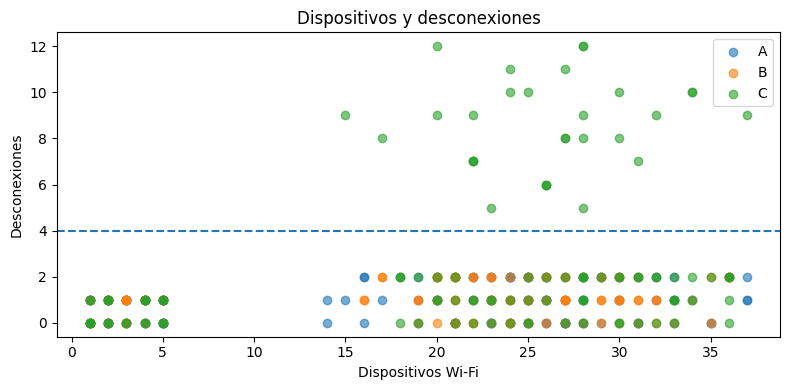

In [5]:
plt.figure(figsize=(8, 4))
for aula in df['aula'].unique():
    datos = df[df['aula']==aula]
    plt.scatter(datos['dispositivos_wifi'],datos['desconexiones'],label=aula,alpha=0.6)
plt.axhline(4,linestyle='--')
plt.xlabel('Dispositivos Wi-Fi')
plt.ylabel('Desconexiones')
plt.title('Dispositivos y desconexiones')
plt.legend()
plt.tight_layout()
plt.savefig('grafica_3.jpg', dpi=150)
plt.show()
plt.close()

## Conclusiones

1. Priorizar C: 342 desconexiones acumuladas, latencia media de 80,17 ms y 30 incidencias (25 % de sus registros). A y B no superan los criterios de incidencia.
2. Las 30 incidencias aparecen en C a las 14, 15 y 16 horas, diez en cada franja. La gráfica temporal muestra la repetición.
3. La correlación de dispositivos con latencia es 0,58 y con desconexiones 0,25. C tiene una media de 20,85 dispositivos frente a 19,77 y 19,80 de A y B; las incidencias ocurren con 15 a 37 dispositivos. Las dispersiones muestran que más dispositivos no implican necesariamente problemas.
4. Hay un registro con cuatro o más desconexiones sin latencia superior a 100 ms, ninguno con solo latencia alta y 29 con ambos criterios.
5. Investigar saturación, interferencias, tareas programadas y el punto de acceso de C. No se puede confirmar ninguna causa con estos datos. Revisar registros del AP, canales, intensidad de señal, retransmisiones y tráfico de subida; repetir pruebas en las franjas afectadas y comparar tasas de incidencias antes y después.